# Bibliometric & Corpus Analysis
Analyzes any IEEE Xplore CSV export using `LiteratureAnalyzer` (`research_analyzer.py`), saving all charts automatically to `output/<csv_name>/`:
1. **Bibliometric & Citation Overview** (Summary table, Document Types, Yearly Trends, Top Venues, Top Authors, Top Cited)
2. **Keyword Tables, Co-occurrence Tables & 3-Period Term Evolution** (see where research is heading across 3 year groups)
3. **Voyant Tools-Style Corpus Analysis** (Corpus Summary, Cirrus Word Cloud, Term Trends, KWIC Contexts, Collocates, Bigrams & TF-IDF)

In [145]:
%load_ext autoreload
%autoreload 2

from IPython.display import display

from research_analyzer import LiteratureAnalyzer

# Change this path to analyze any other CSV; images auto-save to output/<csv_stem>/
CSV_PATH = "dataset/internet-of-pets.csv"

analyzer = LiteratureAnalyzer(
    CSV_PATH,
    extra_stopwords=["iot", "internet of things", "internet things", "pet", "pets", "application", "applications", "internet", "things"]
)
print(f"Saving figures to: {analyzer.output_dir}")

display(analyzer.summary())
display(analyzer.document_types_table())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Saving figures to: output\internet-of-pets


,Metric,Value
0,Total Documents,617
1,Publication Year Range,1999 - 2026
2,Total Citations,6723
3,Mean Citations / Doc,10.9
4,Median Citations / Doc,2.0
5,Dataset h-index,39
6,Unique Authors,2171
7,Document Types Count,13


,Document Type,Count,Share (%)
0,IEEE Conferences,495,80.23
1,IEEE Journals,84,13.61
2,IEEE Magazines,13,2.11
3,IET Conferences,6,0.97
4,Wiley-IEEE Press eBook Chapters,5,0.81
5,IEEE Early Access Articles,3,0.49
6,Wiley AI eBook Chapters,3,0.49
7,MIT Press eBook Chapters,2,0.32
8,Wiley Data and Cybersecurity eBook Chapters,2,0.32
9,Manning eBooks,1,0.16


## 1. Bibliometric & Citation Analytics

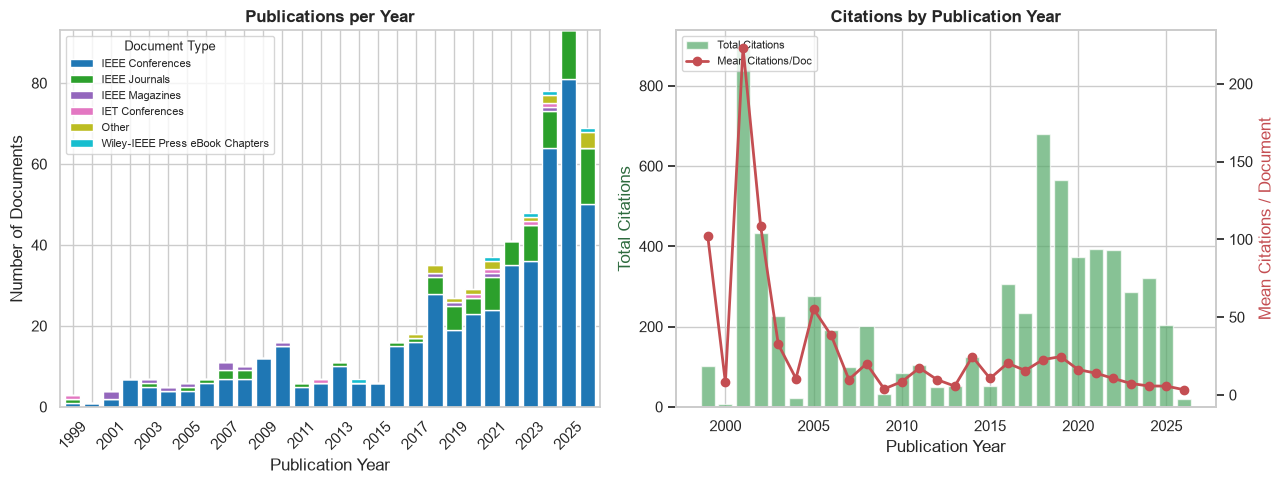

In [146]:
analyzer.plot_publications_and_citations_over_time(save_as="01_publications_and_citations.png");

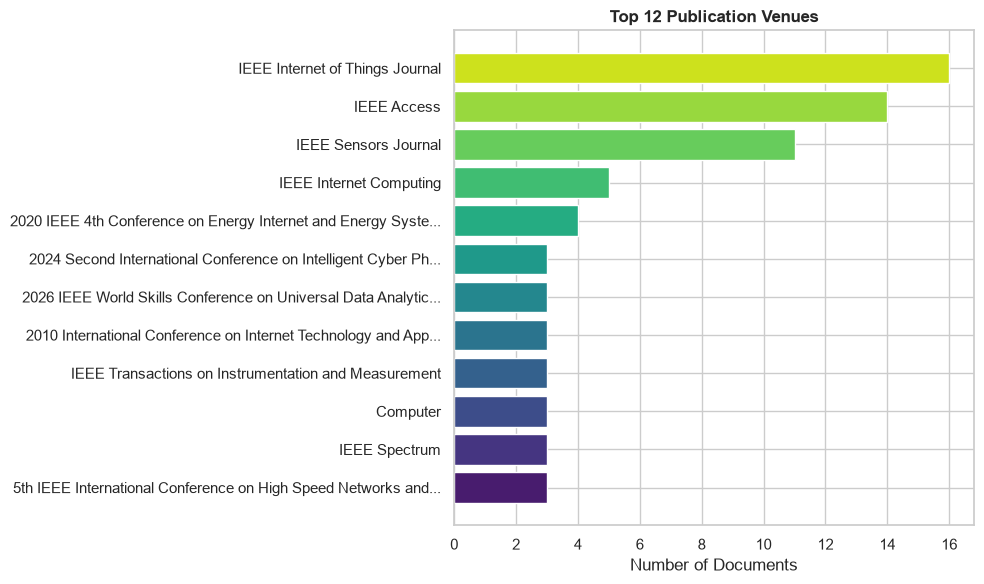

In [147]:
analyzer.plot_top_venues(top_n=12, save_as="02_top_venues.png");

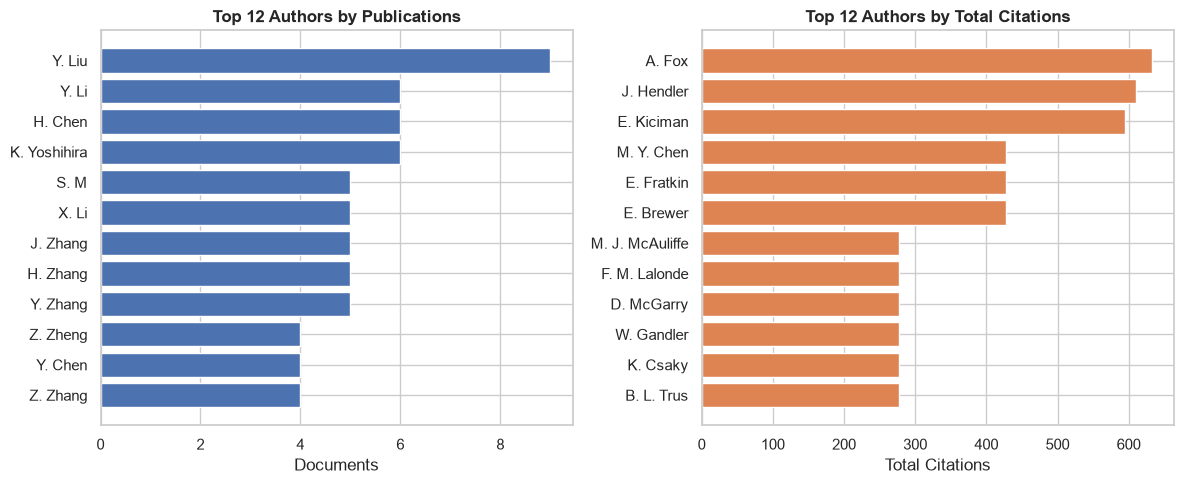

In [148]:
analyzer.plot_top_authors(top_n=12, save_as="03_top_authors.png");

In [149]:
print("Top 10 Most Cited Documents:")
display(analyzer.top_cited_papers(top_n=10))

Top 10 Most Cited Documents:


,Document Title,Authors,Publication Year,Publication Title,Document Identifier,Article Citation Count
0,Agents and the Semantic Web,J. Hendler,2001,IEEE Intelligent Systems,IEEE Magazines,610.0
1,"Pinpoint: problem determination in large, dyna...",M. Y. Chen; E. Kiciman; E. Fratkin; A. Fox; E....,2002,Proceedings International Conference on Depend...,IEEE Conferences,428.0
2,"Medical Image Processing, Analysis and Visuali...",M. J. McAuliffe; F. M. Lalonde; D. McGarry; W....,2001,Proceedings 14th IEEE Symposium on Computer-Ba...,IEEE Conferences,277.0
3,"Privacy in the Smart City—Applications, Techno...",D. Eckhoff; I. Wagner,2018,IEEE Communications Surveys & Tutorials,IEEE Journals,252.0
4,Detecting application-level failures in compon...,E. Kiciman; A. Fox,2005,IEEE Transactions on Neural Networks,IEEE Journals,119.0
5,Crawling AJAX by Inferring User Interface Stat...,A. Mesbah; E. Bozdag; A. van Deursen,2008,2008 Eighth International Conference on Web En...,IEEE Conferences,119.0
6,Autonomous Semantic Web services,M. Paolucci; K. Sycara,2003,IEEE Internet Computing,IEEE Magazines,119.0
7,Privacy in Internet of Things: From Principles...,C. Li; B. Palanisamy,2019,IEEE Internet of Things Journal,IEEE Journals,117.0
8,Fiber-Optic Michelson Interferometric Acoustic...,L. Liu; P. Lu; H. Liao; S. Wang; W. Yang; D. L...,2016,IEEE Sensors Journal,IEEE Journals,116.0
9,Post-Quantum Era Privacy Protection for Intell...,L. Malina; P. Dzurenda; S. Ricci; J. Hajny; G....,2021,IEEE Access,IEEE Journals,108.0


## 2. Keyword Tables, Co-occurrences & 3-Period Term Evolution
Tables of top keywords and co-occurring pairs, plus term counts split across **3 publication year groups** to see where the research is going.

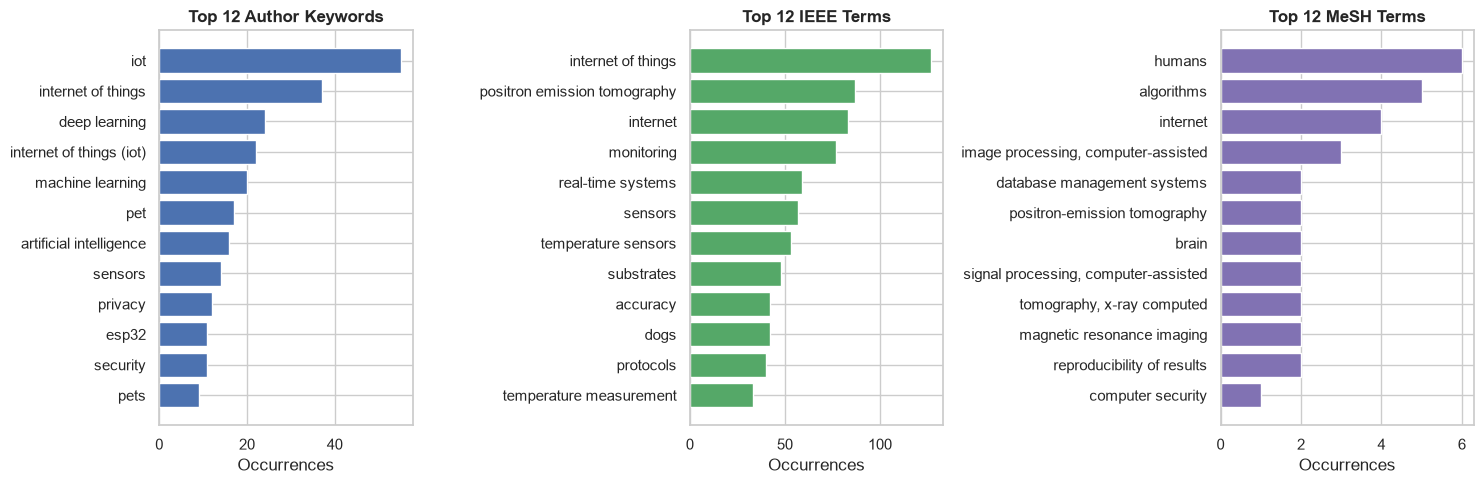

In [150]:
analyzer.plot_keyword_comparison(top_n=12, save_as="04_keyword_comparison.png");

In [151]:
print("Top 15 Author Keywords (with Avg. Year & Citations):")
display(analyzer.top_keywords_table("author_keywords", top_n=15))

print("\nTop 15 Co-occurring Author Keyword Pairs:")
display(analyzer.top_cooccurring_pairs("author_keywords", min_cooccurrences=3, top_n=15))

print("\nTop 15 Co-author Collaborations:")
display(analyzer.top_cooccurring_pairs("authors", min_cooccurrences=2, top_n=15, lowercase=False))

Top 15 Author Keywords (with Avg. Year & Citations):


,Term,Occurrences,Docs (%),Avg. Year,Avg. Citations
0,iot,55,8.91,2021.7,7.83
1,internet of things,37,6.00,2021.2,11.57
2,deep learning,24,3.89,2023.5,6.12
3,internet of things (iot),22,3.57,2022.7,31.06
4,machine learning,20,3.24,2023.0,11.83
5,pet,17,2.76,2022.4,3.67
6,artificial intelligence,16,2.59,2024.4,10.38
7,sensors,14,2.27,2021.4,14.20
8,privacy,12,1.94,2017.2,59.80
9,esp32,11,1.78,2024.7,4.00



Top 15 Co-occurring Author Keyword Pairs:


,Item 1,Item 2,Co-occurrences,Avg. Year
0,iot,sensors,6,2020.8
1,deep learning,image classification,5,2023.0
2,internet of things,pet feeder,4,2019.8
3,esp32,iot,4,2024.0
4,deep learning,machine learning,4,2021.8
5,internet of things,security,4,2020.5
6,internet of things,iot,4,2020.8
7,iot,smart home,4,2020.2
8,privacy,security,4,2020.0
9,activity recognition,internet of things,3,2022.7



Top 15 Co-author Collaborations:


,Item 1,Item 2,Co-occurrences,Avg. Year
0,G. Jiang,H. Chen,4,2007.0
1,G. Jiang,K. Yoshihira,4,2007.0
2,H. Chen,K. Yoshihira,4,2007.0
3,H. Anam,S. M. Abbas,4,2023.8
4,H. Anam,S. Mukhopadhyay,4,2023.8
5,S. M. Abbas,S. Mukhopadhyay,4,2023.8
6,J. Kim,L. Constantinescu,3,2009.7
7,A. Fox,E. Kiciman,3,2003.3
8,A. Farhad,J. -Y. Pyun,3,2022.0
9,B. Wang,C. Wu,3,2024.7


Author Keywords across 3 Year Groups (auto-split into balanced periods):


,Term,1999-2019 (n=222),2020-2024 (n=233),2025-2026 (n=162),Total,Share Shift (pp)
0,iot,12,33,10,55,+0.77
1,internet of things,12,20,5,37,-2.32
2,deep learning,1,13,10,24,+5.72
3,internet of things (iot),4,11,7,22,+2.52
4,machine learning,1,13,6,20,+3.25
5,pet,3,10,4,17,+1.12
6,artificial intelligence,0,9,7,16,+4.32
7,sensors,4,8,2,14,-0.57
8,privacy,9,2,1,12,-3.44
9,esp32,0,4,7,11,+4.32


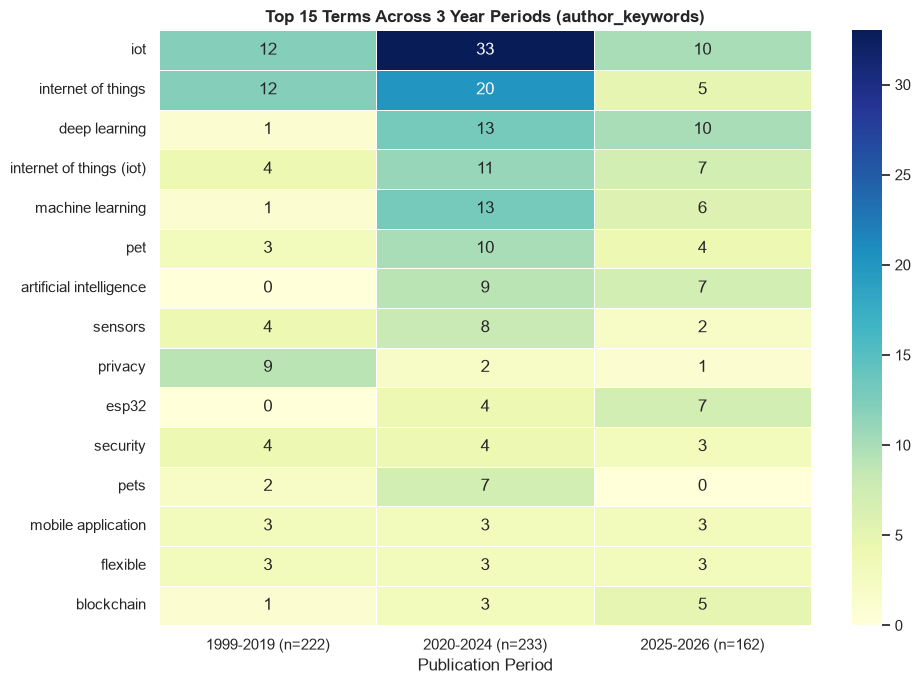

In [152]:
# 3-Year-Group Term Evolution: Author Keywords
print("Author Keywords across 3 Year Groups (auto-split into balanced periods):")
display(analyzer.term_counts_by_year_groups(source="author_keywords", top_n=20))

analyzer.plot_term_evolution_by_year_groups(
    source="author_keywords",
    top_n=15,
    save_as="05_keywords_3_year_groups.png"
);

Corpus Terms (Titles + Abstracts) across 3 Year Groups:


,Term,1999-2019 (n=222),2020-2024 (n=233),2025-2026 (n=162),Total,Share Shift (pp)
0,time,49,57,36,142,+0.15
1,smart,32,60,45,137,+13.36
2,monitoring,22,67,43,132,+16.63
3,model,32,39,61,132,+23.24
4,devices,32,63,29,124,+3.49
5,performance,28,48,47,123,+16.40
6,design,33,43,45,121,+12.91
7,technology,31,59,29,119,+3.94
8,control,32,51,31,114,+4.72
9,information,55,29,28,112,-7.49


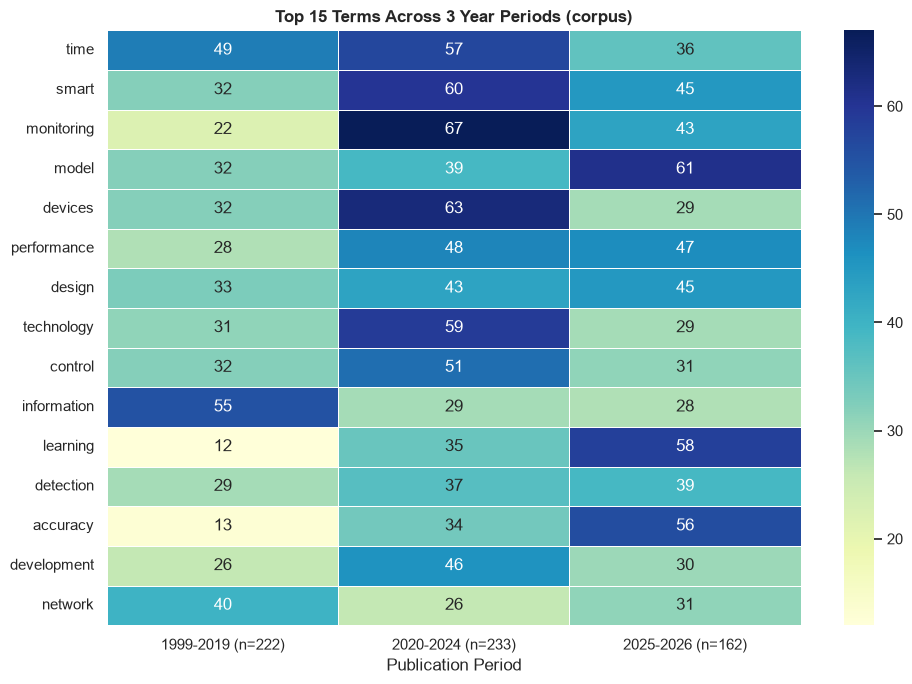

In [153]:
# 3-Year-Group Term Evolution: Corpus (Titles + Abstracts)
print("Corpus Terms (Titles + Abstracts) across 3 Year Groups:")
display(analyzer.term_counts_by_year_groups(source="corpus", top_n=20))

analyzer.plot_term_evolution_by_year_groups(
    source="corpus",
    top_n=15,
    save_as="06_corpus_3_year_groups.png"
);

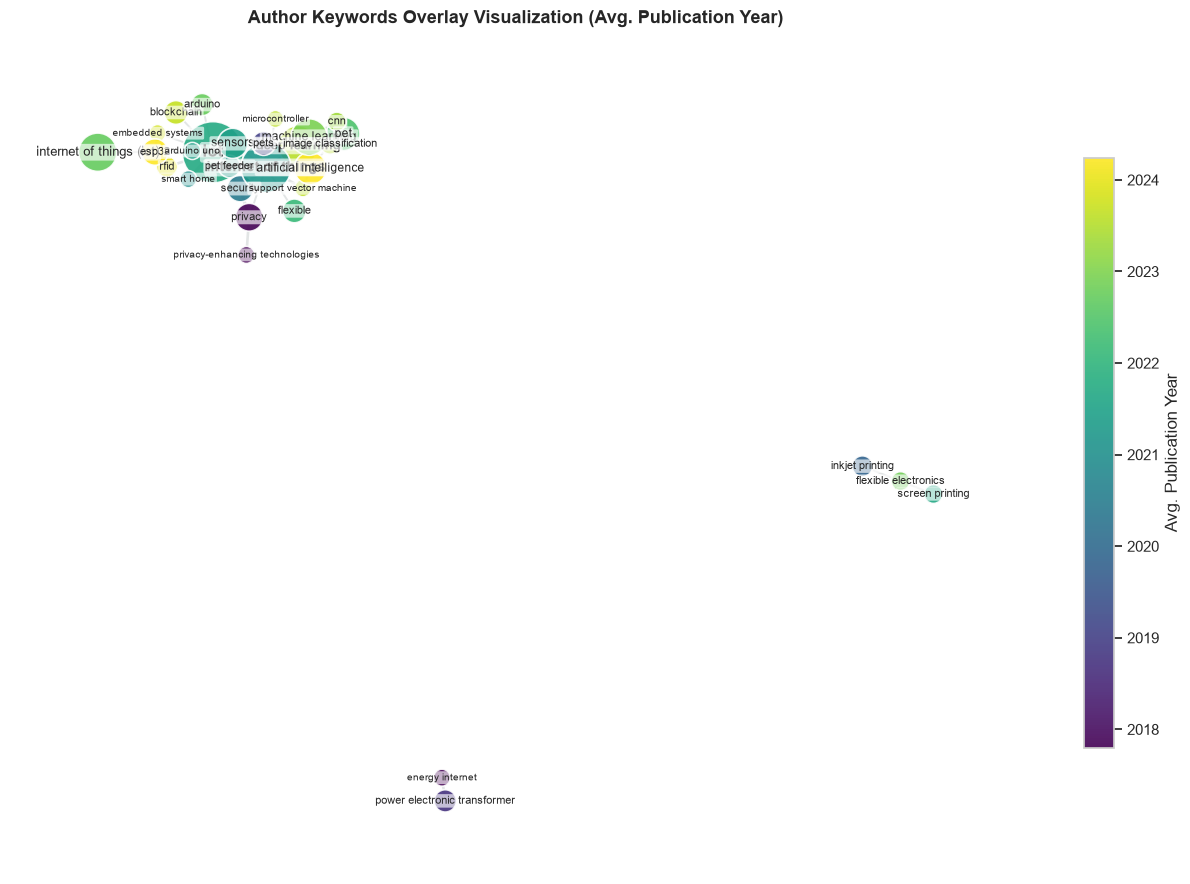

In [154]:
# VOSviewer Overlay Visualization (colored by Average Publication Year, no clusters)
kw_net = analyzer.build_cooccurrence_network(
    col_key="author_keywords",
    min_occurrences=5,
    top_n_nodes=55,
    min_edge_weight=2
)
analyzer.plot_vosviewer_overlay(
    kw_net,
    color_by="avg_year",
    title="Author Keywords Overlay Visualization (Avg. Publication Year)",
    save_as="07_vos_keywords_overlay_year.png"
);

## 3. Voyant Tools-Style Corpus & Text Analysis
Analyzing Titles and Abstracts with **Corpus Summary**, **Cirrus (Word Cloud)**, **Term Trends**, **KWIC (Contexts)**, **Collocates**, **Bigrams**, and **TF-IDF Distinctive Terms**.

In [155]:
display(analyzer.corpus_summary())

,Corpus Metric,Value
0,Documents with Text,617.0000
1,Total Content Words,63430.0000
2,Unique Word Forms,10426.0000
3,Vocabulary Density (TTR),0.1644
4,Avg. Words per Document,102.8000


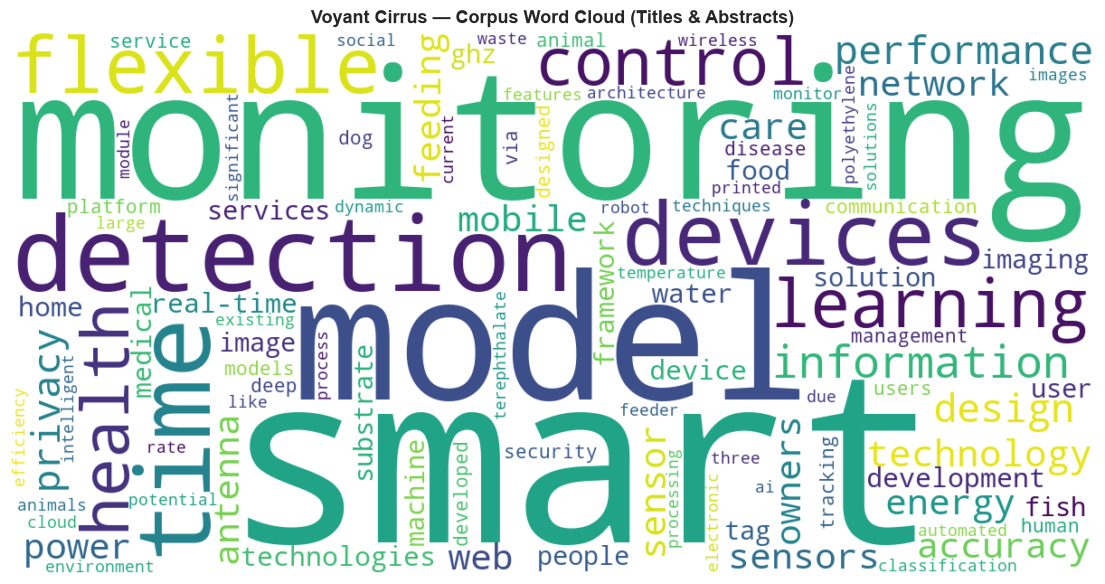

In [156]:
analyzer.plot_cirrus(max_words=100, save_as="08_voyant_cirrus.png");

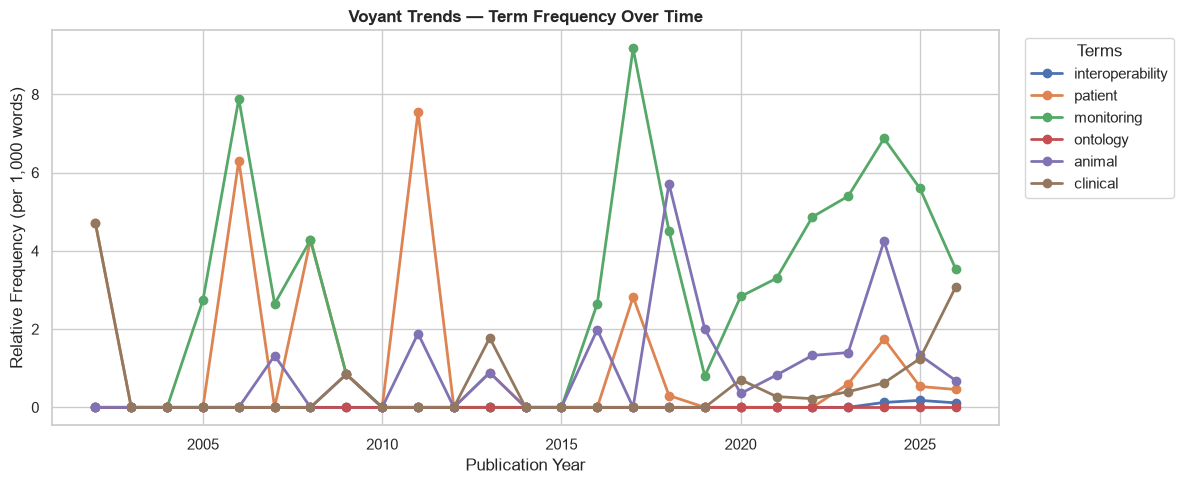

In [157]:
# Voyant Trends: track key research themes over time
analyzer.plot_term_trends(
    terms=["interoperability", "patient", "monitoring", "ontology", "animal", "clinical"],
    min_docs_per_year=5,
    save_as="09_voyant_trends.png"
);

In [158]:
# Voyant Contexts (KWIC) & Collocates for "interoperability"
print("Collocates of 'interoperability':")
display(analyzer.collocates("interoperability", window=5, top_n=12))

print("\nKeywords in Context (KWIC) for 'interoperability':")
display(analyzer.kwic("interoperability", window=6, max_rows=10))

Collocates of 'interoperability':


,Collocate,Co-occurrences
0,performance,2
1,autonomous,1
2,robotic,1
3,assistance,1
4,cross,1
5,platform,1
6,etc,1
7,technology,1
8,makes,1
9,ai,1



Keywords in Context (KWIC) for 'interoperability':


,Year,Document Title,Left Context,Keyword,Right Context
0,2025,PawSense: AI-IoT Enabled Smart Pet Care for Re...,autonomous robotic pet assistance cross platform,interoperability,etc This technology makes use of
1,2024,An IoMT-Based Wearable Thermography System for...,detection capability habitronic features optim...,interoperability,and improved security and reliability Research
2,2026,Privacy Technology and Tools...,is placed on scalability performance optimization,interoperability,and user friendly implementation Key considera...
3,2025,Trusted Medical Imaging: A Blockchain Enabled ...,tend to exist in silos without,interoperability,traceability of data and trust To


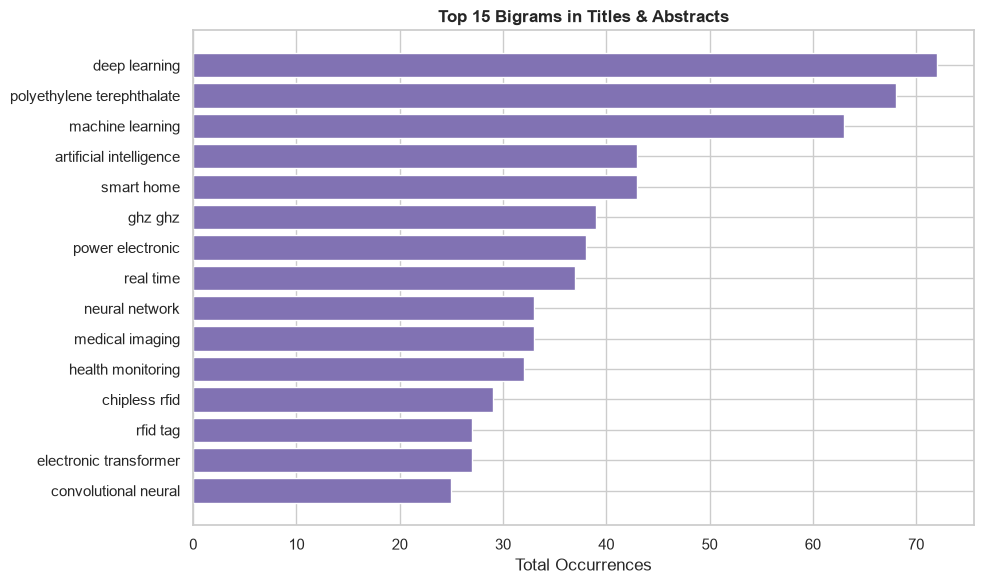

In [159]:
analyzer.plot_ngrams(ngram_range=(2, 2), top_n=15, save_as="10_top_bigrams.png");

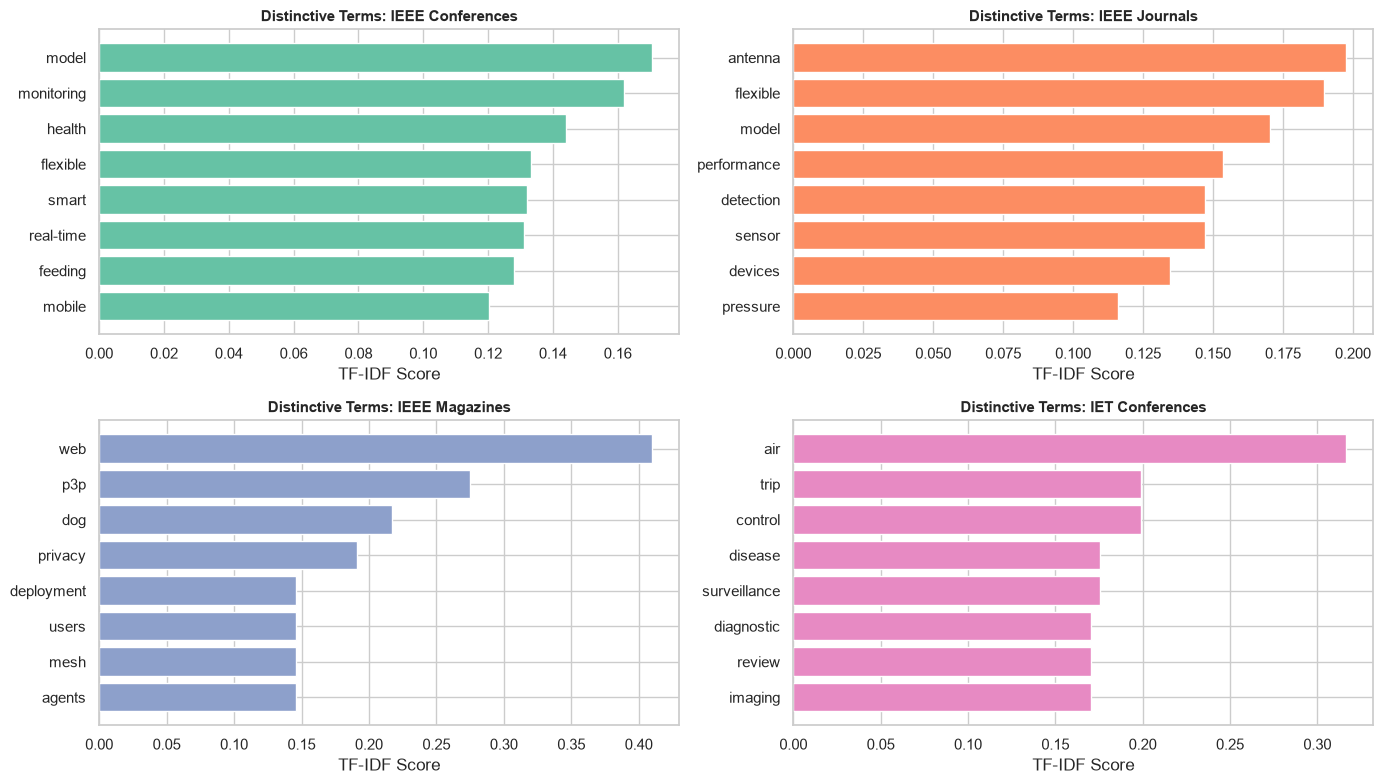

In [160]:
analyzer.plot_distinctive_terms_by_group(group_col_key="doc_type", top_n=8, save_as="11_tfidf_by_doctype.png");